# 1. Setup dell'Ambiente e Dipendenze

## Allineamento Versioni PyTorch e CUDA
Per usare la GPU P100 installo versione **PyTorch 2.10.0** e **TorchVision 0.25.0** compilate per **CUDA 12.6**. 



In [1]:
%pip uninstall -y torch torchvision torchaudio -q
%pip install --no-cache-dir \
    torch==2.10.0 torchvision==0.25.0 torchaudio==2.10.0 \
    --index-url https://download.pytorch.org/whl/cu126 -q

Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 193.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 340.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 219.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 162.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 188.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 185.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.2/158.2 MB 173.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.6/216.6 MB 204.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.3/89.3 kB 296.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.7/19.7 MB 180.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 268.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84

# 2. Configurazione Globale e Inizializzazione

## Riproducibilità e Configurazione Hardware
Impostiamo il seed casuale (`SEED = 42`) su tutte le librerie utilizzate (`random`, `numpy`, `torch` CPU e GPU) per garantire che i pesi iniziali dei modelli, l'ordine dei batch e la data augmentation siano **riproducibili**. 

Definisco inoltre le costanti relative ai percorsi delle cartelle 

In [2]:
import os, random, gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("GPU non disponibile.")

device = torch.device("cuda")
print(f"PyTorch {torch.__version__} | GPU: {torch.cuda.get_device_name(0)}")

DATA_DIR = Path("/kaggle/input/competitions/uni-na-ml-25-26-parasite-egg-classification-contest")
TRAIN_CSV         = DATA_DIR / "train.csv"
TRAIN_DIR         = DATA_DIR / "train"
TEST_DIR          = DATA_DIR / "test"
SUBMISSION_SAMPLE = DATA_DIR / "submission_sample.csv"

PyTorch 2.10.0+cu126 | GPU: Tesla P100-PCIE-16GB


# 3. Caricamento Dataset e Mappatura Classi

## Associazione id classi-nomi parassiti
Eseguiamo il parsing del file CSV principale. Per facilitare l'analisi visiva e il debug degli errori, mappiamo gli ID numerici delle classi nei rispettivi **nomi scientifici dei parassiti** (es. *Fasciola hepatica*, *Nematodirus*). 

Creiamo inoltre la colonna `session_group` che raggruppa le immagini in base alla cartella di appartenenza (sessione) per la validazione robusta.

In [3]:
train_df             = pd.read_csv(TRAIN_CSV)
submission_sample_df = pd.read_csv(SUBMISSION_SAMPLE)

train_df["full_path"]     = train_df["path"].apply(lambda p: str(DATA_DIR / p))
train_df["session_group"] = train_df["path"].apply(lambda p: Path(p).parent.name)

CLASS_NAMES = {
    1: "Gastrointestinal strongyles", 3: "Fasciola hepatica",
    5: "Calicophoron daubneyi",       7: "Nematodirus",       8: "Bubble",
    15: "Strongyloides",             17: "Moniezia benedeni",
    20: "Ascaris lumbricoides",      21: "Ancylostoma duodenale", 22: "Trichuris trichiuria"
}

class_labels   = sorted(train_df["class_label"].unique().tolist())
label_to_index = {lbl: idx for idx, lbl in enumerate(class_labels)}
index_to_label = {idx: lbl for lbl, idx in label_to_index.items()}
NUMERO_CLASSI  = len(class_labels)

train_df["target"]     = train_df["class_label"].map(label_to_index).astype(int)
train_df["class_name"] = train_df["class_label"].map(CLASS_NAMES)

print(f"Classi: {class_labels}")
print(f"Training: {len(train_df)} immagini | Test: {len(list(TEST_DIR.glob('test_patch_*.jpg')))} immagini")

Classi: [1, 3, 5, 7, 8, 15, 17, 20, 21, 22]
Training: 12563 immagini | Test: 3138 immagini


# 4. Visualizzazione dei dati
## Ispezione Visiva dei Campioni
Visualizziamo un'immagine casuale per ciascuna delle 10 classi per avere una idea sulle caratteristiche delle classi 

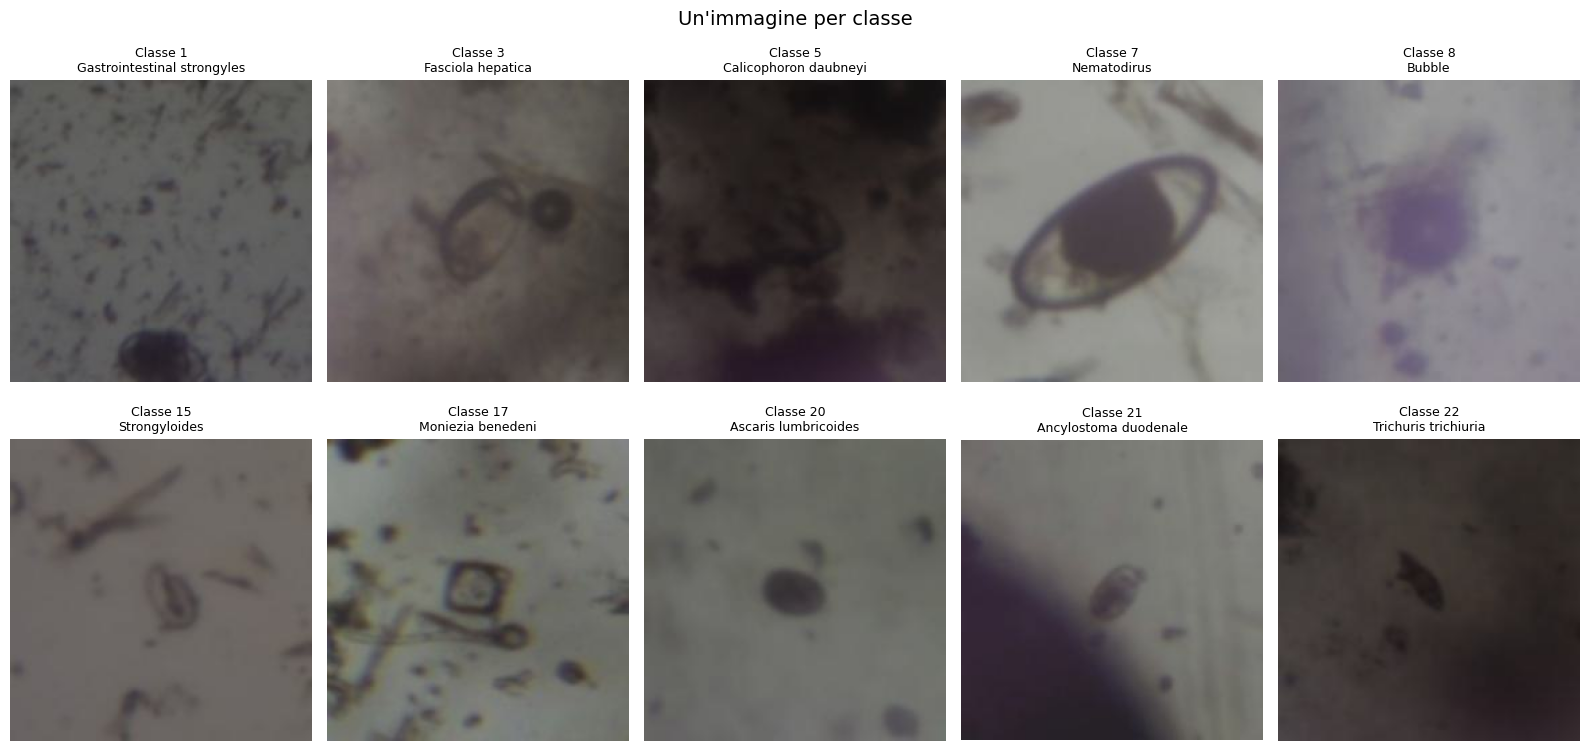

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

esempi = (train_df.groupby("class_label", group_keys=False)
          .sample(n=1, random_state=SEED).sort_values("class_label"))

plt.figure(figsize=(16, 8))
for pos, (_, row) in enumerate(esempi.iterrows(), 1):
    img = Image.open(row["full_path"]).convert("RGB")
    plt.subplot(2, 5, pos)
    plt.imshow(img)
    plt.title(f"Classe {row['class_label']}\n{row['class_name']}", fontsize=9)
    plt.axis("off")
plt.suptitle("Un'immagine per classe", fontsize=14)
plt.tight_layout(); plt.show()

## Isolamento di un Test Interno (Hold-out)

Prima di costruire i successivi split di **training e validation**, isoliamo una parte del dataset etichettato originale come **test interno**. In questo modo possiamo ottenere una stima più indipendente delle prestazioni del modello. Per costruire il test interno utilizziamo **StratifiedKFold** con `n_splits = 5` e selezioniamo il **Fold 0** come hold-out. In questo modo circa il **20% dei dati** viene assegnato al test interno, mentre il restante **80% costituisce il `train_pool`**, che verrà successivamente utilizzato per creare training e validation. La stratificazione viene effettuata rispetto alla variabile `target` e permette di mantenere, per quanto possibile, proporzioni simili delle 10 classi nei due sottoinsiemi.
Il test interno verrà mantenuto separato durante le successive fasi di training e validation e utilizzato successivamente per valutare il sistema finale.

In [5]:
from sklearn.model_selection import StratifiedKFold

NUMERO_FOLD_TEST = 5  # ~20% dei dati come test interno
SEED_TEST_SPLIT = 99
FOLD_TEST_SCELTO = 0

suddivisione_test = StratifiedKFold(
    n_splits=NUMERO_FOLD_TEST, shuffle=True, random_state=SEED_TEST_SPLIT
)

train_pool_df = test_interno_df = None
for n_fold, (idx_pool, idx_test) in enumerate(
    suddivisione_test.split(train_df, train_df["target"])
):
  if n_fold == FOLD_TEST_SCELTO:
    train_pool_df = train_df.iloc[idx_pool].reset_index(drop=True)
    test_interno_df = train_df.iloc[idx_test].reset_index(drop=True)
    break

print(
    f"Train pool (per CV): {len(train_pool_df)} ({train_pool_df['target'].nunique()} classi) | Test interno: {len(test_interno_df)} ({test_interno_df['target'].nunique()} classi)"
)


Train pool (per CV): 10050 (10 classi) | Test interno: 2513 (10 classi)


# 5. Strategia di Validation

## Split Stratificato con StratifiedKFold

Il `train_pool_df`, ottenuto dopo aver isolato il test interno, viene ulteriormente suddiviso in **training e validation**.

Utilizziamo **StratifiedKFold** con 4 fold per mantenere il più possibile la distribuzione delle 10 classi nei due sottoinsiemi. Selezioniamo il **Fold 3** come validation: circa il 75% del train pool viene quindi utilizzato per il training e il restante 25% per la validation.


In [6]:
NUMERO_FOLD = 4
SEED_SPLIT = 50
FOLD_SCELTO = 3

suddivisione_controllo = StratifiedKFold(
    n_splits=NUMERO_FOLD, shuffle=True, random_state=SEED_SPLIT
)

train_split_df = val_split_df = None
for n_fold, (idx_tr, idx_val) in enumerate(
    suddivisione_controllo.split(train_pool_df, train_pool_df["target"])
):
  if n_fold == FOLD_SCELTO:
    train_split_df = train_pool_df.iloc[idx_tr].reset_index(drop=True)
    val_split_df = train_pool_df.iloc[idx_val].reset_index(drop=True)
    break

print(
    f"Fold {FOLD_SCELTO}: train={len(train_split_df)} ({train_split_df['target'].nunique()} classi) | val={len(val_split_df)} ({val_split_df['target'].nunique()} classi)"
)


Fold 3: train=7538 (10 classi) | val=2512 (10 classi)


## Verifica di Distribuzione delle Classi
Generiamo un grafico per verificare che la proporzione originaria delle classi sia stata mantenuta inalterata nei due set dopo la stratificazione, garantendo l'affidabilità delle metriche calcolate sul validation.

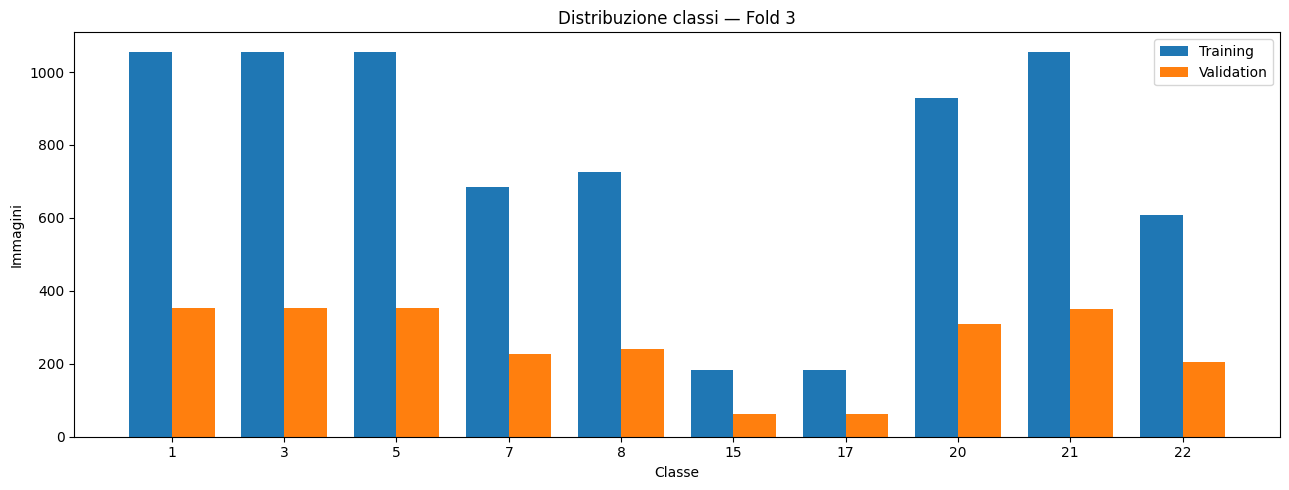

In [7]:
cnt_tr  = train_split_df["class_label"].value_counts().reindex(class_labels, fill_value=0).sort_index()
cnt_val = val_split_df["class_label"].value_counts().reindex(class_labels, fill_value=0).sort_index()

pos = np.arange(len(class_labels)); w = 0.38
plt.figure(figsize=(13, 5))
plt.bar(pos - w/2, cnt_tr.values,  width=w, label="Training")
plt.bar(pos + w/2, cnt_val.values, width=w, label="Validation")
plt.xticks(pos, class_labels)
plt.xlabel("Classe"); plt.ylabel("Immagini")
plt.title("Distribuzione classi — Fold 3")
plt.legend(); plt.tight_layout(); plt.show()

# 6. Pipeline di Augmentation e Normalizzazione

## Data Augmentation 
Per costringere la rete neurale a focalizzarsi esclusivamente sulla struttura morfologica delle uova ed ignorare le variazioni cromatiche dei vetrini, applichiamo:
- Ridimensionamento geometrico a **224x224** (risoluzione nativa di ConvNeXt-Tiny).
- Rotazioni casuali fino a 20 gradi e ribaltamenti speculari (Flip Orizzontale/Verticale).
- Variazioni di luminosità e contrasto (`ColorJitter`) per simulare diverse intensità luminose dei microscopi.
- Normalizzazione standard ImageNet.

In [8]:
from torchvision import transforms

DIMENSIONE_IMMAGINE = 224

trasformazioni_train = transforms.Compose([
    transforms.Resize((DIMENSIONE_IMMAGINE, DIMENSIONE_IMMAGINE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20, fill=0),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

trasformazioni_validation = transforms.Compose([
    transforms.Resize((DIMENSIONE_IMMAGINE, DIMENSIONE_IMMAGINE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

## Generazione dei Dataset e Loader per il Fold 3
Definiamo la classe `DatasetParassiti` per gestire il caricamento "lazy" delle immagini. I dataloader sono ottimizzati con `pin_memory=True` (migliora il trasferimento dati CPU-GPU) e `persistent_workers=True`.

In [9]:
from torch.utils.data import Dataset, DataLoader

class DatasetParassiti(Dataset):
    def __init__(self, dataframe, trasformazioni=None):
        self.df = dataframe.reset_index(drop=True).copy()
        self.trasformazioni = trasformazioni
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        with Image.open(row["full_path"]) as f:
            img = f.convert("RGB")
        if self.trasformazioni: img = self.trasformazioni(img)
        return img, int(row["target"])

dataset_train = DatasetParassiti(train_split_df, trasformazioni_train)
dataset_val   = DatasetParassiti(val_split_df,   trasformazioni_validation)

BATCH = 32; WORKERS = 2
loader_train = DataLoader(
    dataset_train, batch_size=BATCH, shuffle=True,
    num_workers=WORKERS, pin_memory=True, persistent_workers=True)
loader_validation = DataLoader(
    dataset_val, batch_size=BATCH, shuffle=False,
    num_workers=WORKERS, pin_memory=True, persistent_workers=True)
print(f"Batch train: {len(loader_train)} | Batch val: {len(loader_validation)}")

Batch train: 236 | Batch val: 79


# 7. Definizione Modello e Funzioni di Addestramento

## Scelte Tecniche e Gestione dello Sbilanciamento
- **Backbone:** Usiamo `ConvNeXt-Tiny` pre-addestrato su ImageNet. È un'architettura moderna a convoluzioni che unisce l'efficienza dei Transformer all'invarianza spaziale delle CNN.
- **Regularization:** Inseriamo un layer di `Dropout(p=0.20)` prima del classificatore lineare per contrastare l'overfitting.
- **Loss pesata:** Per contrastare lo sbilanciamento delle classi (alcune specie sono molto rare), calcoliamo pesi inversamente proporzionali alla radice delle frequenze delle classi e li passiamo alla `CrossEntropyLoss`.
- **Precisione Mista:** Il ciclo di training è accelerato tramite precisione FP16 (`torch.amp.autocast`).

In [10]:
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from tqdm.auto import tqdm

def crea_modello():
    mod = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
    feat_in = mod.classifier[2].in_features
    mod.classifier[2] = nn.Sequential(
        nn.Dropout(p=0.20), nn.Linear(feat_in, NUMERO_CLASSI))
    return mod.to(device)

def crea_criterio(split_df):
    cnt = (split_df["target"].value_counts()
           .reindex(range(NUMERO_CLASSI), fill_value=0).sort_index())
    w = 1.0 / torch.sqrt(torch.tensor(cnt.values, dtype=torch.float32))
    w = w / w.mean()
    return nn.CrossEntropyLoss(weight=w.to(device), label_smoothing=0.05)

def addestra_un_epoca(modello, loader, criterio, ottimizzatore, scaler, backbone_congelato):
    modello.train()
    if backbone_congelato: modello.features.eval()
    perdita_tot, etichette, predizioni = 0.0, [], []
    for imgs, target in tqdm(loader, desc="Train", leave=False):
        imgs   = imgs.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        ottimizzatore.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            out  = modello(imgs)
            loss = criterio(out, target)
        scaler.scale(loss).backward()
        scaler.unscale_(ottimizzatore)
        torch.nn.utils.clip_grad_norm_(modello.parameters(), max_norm=1.0)
        scaler.step(ottimizzatore); scaler.update()
        perdita_tot += loss.item() * imgs.size(0)
        predizioni.extend(out.argmax(1).detach().cpu().tolist())
        etichette.extend(target.detach().cpu().tolist())
    return {"loss": perdita_tot / len(loader.dataset),
            "accuracy": accuracy_score(etichette, predizioni),
            "balanced_accuracy": balanced_accuracy_score(etichette, predizioni)}

@torch.inference_mode()
def valuta_modello(modello, loader, criterio):
    modello.eval()
    perdita_tot, etichette, predizioni = 0.0, [], []
    for imgs, target in tqdm(loader, desc="Val", leave=False):
        imgs   = imgs.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            out  = modello(imgs)
            loss = criterio(out, target)
        perdita_tot += loss.item() * imgs.size(0)
        predizioni.extend(out.argmax(1).cpu().tolist())
        etichette.extend(target.cpu().tolist())
    return {"loss": perdita_tot / len(loader.dataset),
            "accuracy": accuracy_score(etichette, predizioni),
            "balanced_accuracy": balanced_accuracy_score(etichette, predizioni)}

criterio = crea_criterio(train_split_df)
print("Modello, loss e funzioni di training pronti.")

Modello, loss e funzioni di training pronti.


# 8. Addestramento sul Fold 3

## Esperimento 1 — Baseline 12 epoche ad Alto LR
Iniziamo con una configurazione standard a 12 epoche:
- Le prime 2 epoche hanno il backbone congelato ad alto LR ($10^{-3}$) per riscaldare la testa lineare.
- Successivamente, sblocchiamo l'intera rete per 10 epoche con un tasso di apprendimento moderatamente alto.

In [11]:

EPOCHE_CONGELATE = 2; EPOCHE_FT = 10; EPOCHE_TOT = 12
LR_FROZEN = 1e-3; LR_BB = 2e-5; LR_CLS = 1e-4; WD = 1e-4

CKPT_EXP1   = Path("/kaggle/working/convnext_fold3_exp1_best.pth")
STORIA_EXP1 = Path("/kaggle/working/storia_fold3_exp1.csv")

modello = crea_modello()
for p in modello.features.parameters():   p.requires_grad = False
for p in modello.classifier.parameters(): p.requires_grad = True

opt    = torch.optim.AdamW(modello.classifier.parameters(), lr=LR_FROZEN, weight_decay=WD)
sch    = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHE_CONGELATE, eta_min=1e-5)
scaler = torch.amp.GradScaler("cuda")

storia_exp1 = []; best_ba_exp1 = -1.0; best_ep_exp1 = 0

for epoca in range(EPOCHE_TOT):
    if epoca == EPOCHE_CONGELATE:
        for p in modello.parameters(): p.requires_grad = True
        opt = torch.optim.AdamW([
            {"params": modello.features.parameters(),   "lr": LR_BB},
            {"params": modello.classifier.parameters(), "lr": LR_CLS}
        ], weight_decay=WD)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHE_FT, eta_min=1e-6)

    bl   = epoca < EPOCHE_CONGELATE
    fase = "frozen" if bl else "fine-tuning"
    print(f"\nEpoca {epoca+1}/{EPOCHE_TOT} – {fase}")
    tr  = addestra_un_epoca(modello, loader_train, criterio, opt, scaler, bl)
    val = valuta_modello(modello, loader_validation, criterio)
    sch.step()
    ba = val["balanced_accuracy"]
    storia_exp1.append({"epoca": epoca+1, "fase": fase,
        "loss_train": tr["loss"], "loss_validation": val["loss"],
        "balanced_accuracy_train": tr["balanced_accuracy"],
        "balanced_accuracy_validation": ba})
    pd.DataFrame(storia_exp1).to_csv(STORIA_EXP1, index=False)
    ckpt = {"epoca": epoca+1, "model_state_dict": modello.state_dict(),
            "balanced_accuracy": ba,
            "label_to_index": label_to_index, "index_to_label": index_to_label}
    if ba > best_ba_exp1:
        best_ba_exp1 = ba; best_ep_exp1 = epoca+1
        torch.save(ckpt, CKPT_EXP1); print(f"  Best BA = {best_ba_exp1:.4f}")
    print(f"Loss: {tr['loss']:.4f}/{val['loss']:.4f} | BA: {tr['balanced_accuracy']:.4f}/{ba:.4f}")

del modello; gc.collect(); torch.cuda.empty_cache()
print(f"\nEXP1 completato. Best BA: {round(best_ba_exp1,4)} (epoca {best_ep_exp1})")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 175MB/s] 



Epoca 1/12 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

...

Val:   0%|          | 0/79 [00:00<?, ?it/s]

  Best BA = 0.9771
Loss: 0.3910/0.4275 | BA: 0.9850/0.9771

Epoca 12/12 – fine-tuning


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3892/0.4262 | BA: 0.9870/0.9766

EXP1 completato. Best BA: 0.9771 (epoca 11)


## Esperimento 2 — Fine-Tuning Conservativo a LR Basso (18 epoche)

Per verificare se un adattamento più graduale dei pesi pre-addestrati su ImageNet possa migliorare la generalizzazione, riduciamo i learning rate rispetto all'Esperimento 1:

- Fase congelata con LR ridotto (`5e-4`).
- Fine-tuning completo con `1e-5` per il backbone e `5e-5` per il classificatore.
- Estensione del training a **18 epoche totali** per compensare gli aggiornamenti più piccoli.

La migliore Balanced Accuracy di validation ottenuta è **0.9724 all'epoca 16**, inferiore allo **0.9771** dell'Esperimento 1. In questo split, quindi, il fine-tuning più conservativo non ha prodotto un miglioramento.

In [12]:
random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.cuda.manual_seed_all(42)

EPOCHE_CONGELATE_EXP2 = 2; EPOCHE_FT_EXP2 = 16; EPOCHE_TOT_EXP2 = 18
LR_FROZEN_EXP2 = 5e-4; LR_BB_EXP2 = 1e-5; LR_CLS_EXP2 = 5e-5; WD_EXP2 = 1e-4

CKPT_BEST_EXP2 = Path("/kaggle/working/EXP2_convnext_fold3_18ep_lr_basso_best.pth")
CKPT_LAST_EXP2 = Path("/kaggle/working/EXP2_convnext_fold3_18ep_lr_basso_last.pth")
STORIA_EXP2    = Path("/kaggle/working/EXP2_storia_convnext_fold3_18ep_lr_basso.csv")

modello_exp2 = crea_modello()
for p in modello_exp2.features.parameters():   p.requires_grad = False
for p in modello_exp2.classifier.parameters(): p.requires_grad = True

opt_exp2    = torch.optim.AdamW(modello_exp2.classifier.parameters(), lr=LR_FROZEN_EXP2, weight_decay=WD_EXP2)
sch_exp2    = torch.optim.lr_scheduler.CosineAnnealingLR(opt_exp2, T_max=EPOCHE_CONGELATE_EXP2, eta_min=1e-5)
scaler_exp2 = torch.amp.GradScaler("cuda")

storia_exp2 = []; best_ba_exp2 = -1.0; best_ep_exp2 = 0

for epoca in range(EPOCHE_TOT_EXP2):
    if epoca == EPOCHE_CONGELATE_EXP2:
        print("\nScongelamento backbone EXP2...")
        for p in modello_exp2.parameters(): p.requires_grad = True
        opt_exp2 = torch.optim.AdamW([
            {"params": modello_exp2.features.parameters(),   "lr": LR_BB_EXP2},
            {"params": modello_exp2.classifier.parameters(), "lr": LR_CLS_EXP2}
        ], weight_decay=WD_EXP2)
        sch_exp2 = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt_exp2, T_max=EPOCHE_FT_EXP2, eta_min=1e-6)

    bl   = epoca < EPOCHE_CONGELATE_EXP2
    fase = "frozen" if bl else "fine-tuning"
    print(f"\nEpoca {epoca+1}/{EPOCHE_TOT_EXP2} – {fase}")
    tr  = addestra_un_epoca(modello_exp2, loader_train, criterio, opt_exp2, scaler_exp2, bl)
    val = valuta_modello(modello_exp2, loader_validation, criterio)
    sch_exp2.step()
    ba   = val["balanced_accuracy"]
    lr_c = [f"{g['lr']:.2e}" for g in opt_exp2.param_groups]
    storia_exp2.append({"epoca": epoca+1, "fase": fase,
        "loss_train": tr["loss"], "loss_validation": val["loss"],
        "balanced_accuracy_train": tr["balanced_accuracy"],
        "balanced_accuracy_validation": ba, "learning_rate": str(lr_c)})
    pd.DataFrame(storia_exp2).to_csv(STORIA_EXP2, index=False)
    ckpt = {"nome": "EXP2 ConvNeXt Fold3", "epoca": epoca+1,
            "model_state_dict": modello_exp2.state_dict(),
            "optimizer_state_dict": opt_exp2.state_dict(),
            "scheduler_state_dict": sch_exp2.state_dict(),
            "balanced_accuracy": ba,
            "label_to_index": label_to_index, "index_to_label": index_to_label}
    torch.save(ckpt, CKPT_LAST_EXP2)
    if ba > best_ba_exp2:
        best_ba_exp2 = ba; best_ep_exp2 = epoca+1
        torch.save(ckpt, CKPT_BEST_EXP2); print(f"  Best BA = {best_ba_exp2:.4f}")
    print(f"Loss: {tr['loss']:.4f}/{val['loss']:.4f} | BA: {tr['balanced_accuracy']:.4f}/{ba:.4f} | LR: {lr_c}")

del modello_exp2; gc.collect(); torch.cuda.empty_cache()
print(f"\nEXP2 completato. Best BA: {round(best_ba_exp2,4)} (epoca {best_ep_exp2})")


Epoca 1/18 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

  Best BA = 0.7603
Loss: 1.4012/1.0396 | BA: 0.6011/0.7603 | LR: ['2.55e-04']

Epoca 2/18 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

...

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3981/0.4352 | BA: 0.9837/0.9716 | LR: ['1.09e-06', '1.47e-06']

Epoca 18/18 – fine-tuning


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3967/0.4324 | BA: 0.9837/0.9722 | LR: ['1.00e-06', '1.00e-06']

EXP2 completato. Best BA: 0.9724 (epoca 16)


# 9. Cross-Validation: Addestramento del Fold 1

## Preparazione dello Split e dei Dataloader
Prepariamo la divisione sul **Fold 1** per ottenere il secondo modello per l'ensemble finale. Rinizializziamo la memoria della GPU ed i dataloader.

In [13]:
# Libera GPU dagli esperimenti precedenti
for v in [
    "modello",
    "modello_exp2",
    "opt",
    "opt_exp2",
    "sch",
    "sch_exp2",
    "scaler",
    "scaler_exp2",
]:
  if v in globals():
    del globals()[v]
gc.collect()
torch.cuda.empty_cache()

FOLD_SCELTO_FOLD1 = 1
train_fold1_df = val_fold1_df = None
for n_fold, (idx_tr, idx_val) in enumerate(
    suddivisione_controllo.split(train_pool_df, train_pool_df["target"])
):
  if n_fold == FOLD_SCELTO_FOLD1:
    train_fold1_df = train_pool_df.iloc[idx_tr].reset_index(drop=True)
    val_fold1_df = train_pool_df.iloc[idx_val].reset_index(drop=True)
    break

print(
    f"Fold 1: train={len(train_fold1_df)} ({train_fold1_df['target'].nunique()} classi) | val={len(val_fold1_df)} ({val_fold1_df['target'].nunique()} classi)"
)

dataset_train_fold1 = DatasetParassiti(train_fold1_df, trasformazioni_train)
dataset_val_fold1 = DatasetParassiti(val_fold1_df, trasformazioni_validation)
loader_train_fold1 = DataLoader(
    dataset_train_fold1,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)
loader_validation_fold1 = DataLoader(
    dataset_val_fold1,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)
criterio_fold1 = crea_criterio(train_fold1_df)
print(
    f"Batch train: {len(loader_train_fold1)} | Batch val: {len(loader_validation_fold1)}"
)


Fold 1: train=7537 (10 classi) | val=2513 (10 classi)
Batch train: 236 | Batch val: 79


## Addestramento Fold 1 (12 epoche ad Alto LR)
Addestriamo sul Fold 1 con la configurazione da 12 epoche. Il modello converge rapidamente stabilizzandosi a una **Balanced Accuracy locale di 0.9635**.

In [14]:
# fold1 training 12 epoche lr alto
random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.cuda.manual_seed_all(42)

EPOCHE_CONGELATE_F1 = 2; EPOCHE_FT_F1 = 10; EPOCHE_TOT_F1 = 12
LR_FROZEN_F1 = 1e-3; LR_BB_F1 = 2e-5; LR_CLS_F1 = 1e-4; WD_F1 = 1e-4

CKPT_BEST_F1 = Path("/kaggle/working/convnext_fold1_12ep_best.pth")
CKPT_LAST_F1 = Path("/kaggle/working/convnext_fold1_12ep_last.pth")
STORIA_F1    = Path("/kaggle/working/storia_convnext_fold1_12ep.csv")

modello_fold1 = crea_modello()
for p in modello_fold1.features.parameters():   p.requires_grad = False
for p in modello_fold1.classifier.parameters(): p.requires_grad = True

opt_f1    = torch.optim.AdamW(modello_fold1.classifier.parameters(), lr=LR_FROZEN_F1, weight_decay=WD_F1)
sch_f1    = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f1, T_max=EPOCHE_CONGELATE_F1, eta_min=1e-5)
scaler_f1 = torch.amp.GradScaler("cuda")

storia_f1 = []; best_ba_f1 = -1.0; best_ep_f1 = 0

for epoca in range(EPOCHE_TOT_F1):
    if epoca == EPOCHE_CONGELATE_F1:
        print("\nScongelamento backbone Fold 1...")
        for p in modello_fold1.parameters(): p.requires_grad = True
        opt_f1 = torch.optim.AdamW([
            {"params": modello_fold1.features.parameters(),   "lr": LR_BB_F1},
            {"params": modello_fold1.classifier.parameters(), "lr": LR_CLS_F1}
        ], weight_decay=WD_F1)
        sch_f1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f1, T_max=EPOCHE_FT_F1, eta_min=1e-6)

    bl   = epoca < EPOCHE_CONGELATE_F1
    fase = "frozen" if bl else "fine-tuning"
    print(f"\nEpoca {epoca+1}/{EPOCHE_TOT_F1} – {fase}")
    tr  = addestra_un_epoca(modello_fold1, loader_train_fold1, criterio_fold1, opt_f1, scaler_f1, bl)
    val = valuta_modello(modello_fold1, loader_validation_fold1, criterio_fold1)
    sch_f1.step()
    ba   = val["balanced_accuracy"]
    lr_c = [f"{g['lr']:.2e}" for g in opt_f1.param_groups]
    storia_f1.append({"epoca": epoca+1, "fase": fase,
        "loss_train": tr["loss"], "loss_validation": val["loss"],
        "balanced_accuracy_train": tr["balanced_accuracy"],
        "balanced_accuracy_validation": ba, "learning_rate": str(lr_c)})
    pd.DataFrame(storia_f1).to_csv(STORIA_F1, index=False)
    ckpt = {"nome": "ConvNeXt Fold1 12ep", "epoca": epoca+1,
            "model_state_dict": modello_fold1.state_dict(),
            "optimizer_state_dict": opt_f1.state_dict(),
            "scheduler_state_dict": sch_f1.state_dict(),
            "balanced_accuracy": ba,
            "label_to_index": label_to_index, "index_to_label": index_to_label}
    torch.save(ckpt, CKPT_LAST_F1)
    if ba > best_ba_f1:
        best_ba_f1 = ba; best_ep_f1 = epoca+1
        torch.save(ckpt, CKPT_BEST_F1); print(f"  Best BA = {best_ba_f1:.4f}")
    print(f"Loss: {tr['loss']:.4f}/{val['loss']:.4f} | BA: {tr['balanced_accuracy']:.4f}/{ba:.4f} | LR: {lr_c}")

del modello_fold1; gc.collect(); torch.cuda.empty_cache()
print(f"\nFold 1 completato. Best BA: {round(best_ba_f1,4)} (epoca {best_ep_f1})")


Epoca 1/12 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

  Best BA = 0.7914
Loss: 1.1939/0.9174 | BA: 0.6899/0.7914 | LR: ['5.05e-04']

Epoca 2/12 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

...

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3905/0.4310 | BA: 0.9859/0.9710 | LR: ['1.46e-06', '3.42e-06']

Epoca 12/12 – fine-tuning


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3881/0.4323 | BA: 0.9867/0.9697 | LR: ['1.00e-06', '1.00e-06']

Fold 1 completato. Best BA: 0.9731 (epoca 9)


## Addestramento Fold 1 V2 (18 epoche a LR Basso)
Replichiamo l'esperimento a 18 epoche sul Fold 1 per valutarne la stabilità a LR più bassi, raggiungendo una **Balanced Accuracy locale di 0.9596**.

In [15]:
# fold1 18 epoche lr basso
random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.cuda.manual_seed_all(42)

EPOCHE_CONGELATE_F1V2 = 2; EPOCHE_FT_F1V2 = 16; EPOCHE_TOT_F1V2 = 18
LR_FROZEN_F1V2 = 5e-4; LR_BB_F1V2 = 1e-5; LR_CLS_F1V2 = 5e-5; WD_F1V2 = 1e-4

CKPT_BEST_F1V2 = Path("/kaggle/working/convnext_fold1_v2_18ep_lr_basso_best.pth")
CKPT_LAST_F1V2 = Path("/kaggle/working/convnext_fold1_v2_18ep_lr_basso_last.pth")
STORIA_F1V2    = Path("/kaggle/working/storia_fold1_v2_18ep.csv")

modello_f1v2 = crea_modello()
for p in modello_f1v2.features.parameters():   p.requires_grad = False
for p in modello_f1v2.classifier.parameters(): p.requires_grad = True

opt_f1v2    = torch.optim.AdamW(modello_f1v2.classifier.parameters(), lr=LR_FROZEN_F1V2, weight_decay=WD_F1V2)
sch_f1v2    = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f1v2, T_max=EPOCHE_CONGELATE_F1V2, eta_min=1e-5)
scaler_f1v2 = torch.amp.GradScaler("cuda")

storia_f1v2 = []; best_ba_f1v2 = -1.0; best_ep_f1v2 = 0

for epoca in range(EPOCHE_TOT_F1V2):
    if epoca == EPOCHE_CONGELATE_F1V2:
        print("\nScongelamento backbone Fold 1 V2...")
        for p in modello_f1v2.parameters(): p.requires_grad = True
        opt_f1v2 = torch.optim.AdamW([
            {"params": modello_f1v2.features.parameters(),   "lr": LR_BB_F1V2},
            {"params": modello_f1v2.classifier.parameters(), "lr": LR_CLS_F1V2}
        ], weight_decay=WD_F1V2)
        sch_f1v2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f1v2, T_max=EPOCHE_FT_F1V2, eta_min=1e-6)

    bl   = epoca < EPOCHE_CONGELATE_F1V2
    fase = "frozen" if bl else "fine-tuning"
    print(f"\nEpoca {epoca+1}/{EPOCHE_TOT_F1V2} – {fase}")
    tr  = addestra_un_epoca(modello_f1v2, loader_train_fold1, criterio_fold1, opt_f1v2, scaler_f1v2, bl)
    val = valuta_modello(modello_f1v2, loader_validation_fold1, criterio_fold1)
    sch_f1v2.step()
    ba   = val["balanced_accuracy"]
    lr_c = [f"{g['lr']:.2e}" for g in opt_f1v2.param_groups]
    storia_f1v2.append({"epoca": epoca+1, "fase": fase,
        "loss_train": tr["loss"], "loss_validation": val["loss"],
        "balanced_accuracy_train": tr["balanced_accuracy"],
        "balanced_accuracy_validation": ba, "learning_rate": str(lr_c)})
    pd.DataFrame(storia_f1v2).to_csv(STORIA_F1V2, index=False)
    ckpt = {"nome": "ConvNeXt Fold1 V2 18ep LR-basso", "epoca": epoca+1,
            "model_state_dict": modello_f1v2.state_dict(),
            "optimizer_state_dict": opt_f1v2.state_dict(),
            "scheduler_state_dict": sch_f1v2.state_dict(),
            "balanced_accuracy": ba,
            "label_to_index": label_to_index, "index_to_label": index_to_label}
    torch.save(ckpt, CKPT_LAST_F1V2)
    if ba > best_ba_f1v2:
        best_ba_f1v2 = ba; best_ep_f1v2 = epoca+1
        torch.save(ckpt, CKPT_BEST_F1V2); print(f"  Best BA = {best_ba_f1v2:.4f}")
    print(f"Loss: {tr['loss']:.4f}/{val['loss']:.4f} | BA: {tr['balanced_accuracy']:.4f}/{ba:.4f} | LR: {lr_c}")

del modello_f1v2; gc.collect(); torch.cuda.empty_cache()
print(f"\nFold 1 V2 completato. Best BA: {round(best_ba_f1v2,4)} (epoca {best_ep_f1v2})")


Epoca 1/18 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

  Best BA = 0.7575
Loss: 1.4025/1.0498 | BA: 0.6086/0.7575 | LR: ['2.55e-04']

Epoca 2/18 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

...

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3925/0.4346 | BA: 0.9867/0.9693 | LR: ['1.09e-06', '1.47e-06']

Epoca 18/18 – fine-tuning


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3949/0.4342 | BA: 0.9858/0.9691 | LR: ['1.00e-06', '1.00e-06']

Fold 1 V2 completato. Best BA: 0.9696 (epoca 15)


# 10. Modelli Alternativi di Controllo

## EfficientNetV2-S sul Fold 3 (18 epoche)
Al fine di determinare se una diversa architettura possa portare benefici di diversificazione all'ensemble, addestriamo un modello della famiglia EfficientNetV2-S sul Fold 3, mantenendo gli stessi iperparametri.

In [16]:
# prova sull efficientnet non andat abene 
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.cuda.manual_seed_all(42)

EPOCHE_CONGELATE_EFF = 2; EPOCHE_FT_EFF = 16; EPOCHE_TOT_EFF = 18
LR_FROZEN_EFF = 5e-4; LR_BB_EFF = 1e-5; LR_CLS_EFF = 5e-5; WD_EFF = 1e-4

CKPT_BEST_EFF = Path("/kaggle/working/effnetv2s_fold3_best.pth")
CKPT_LAST_EFF = Path("/kaggle/working/effnetv2s_fold3_last.pth")
STORIA_EFF    = Path("/kaggle/working/effnetv2s_fold3_storia.csv")

def crea_effnet():
    mod = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.DEFAULT)
    mod.classifier[1] = nn.Linear(mod.classifier[1].in_features, NUMERO_CLASSI)
    return mod.to(device)

modello_eff = crea_effnet()
for p in modello_eff.features.parameters():   p.requires_grad = False
for p in modello_eff.classifier.parameters(): p.requires_grad = True

opt_eff    = torch.optim.AdamW(modello_eff.classifier.parameters(), lr=LR_FROZEN_EFF, weight_decay=WD_EFF)
sch_eff    = torch.optim.lr_scheduler.CosineAnnealingLR(opt_eff, T_max=EPOCHE_CONGELATE_EFF, eta_min=1e-5)
scaler_eff = torch.amp.GradScaler("cuda")

storia_eff = []; best_ba_eff = -1.0; best_ep_eff = 0

for epoca in range(EPOCHE_TOT_EFF):
    if epoca == EPOCHE_CONGELATE_EFF:
        print("\nScongelamento backbone EfficientNet...")
        for p in modello_eff.parameters(): p.requires_grad = True
        opt_eff = torch.optim.AdamW([
            {"params": modello_eff.features.parameters(),   "lr": LR_BB_EFF},
            {"params": modello_eff.classifier.parameters(), "lr": LR_CLS_EFF}
        ], weight_decay=WD_EFF)
        sch_eff = torch.optim.lr_scheduler.CosineAnnealingLR(opt_eff, T_max=EPOCHE_FT_EFF, eta_min=1e-6)

    bl   = epoca < EPOCHE_CONGELATE_EFF
    fase = "frozen" if bl else "fine-tuning"
    print(f"\nEpoca {epoca+1}/{EPOCHE_TOT_EFF} – {fase}")
    tr  = addestra_un_epoca(modello_eff, loader_train, criterio, opt_eff, scaler_eff, bl)
    val = valuta_modello(modello_eff, loader_validation, criterio)
    sch_eff.step()
    ba   = val["balanced_accuracy"]
    lr_c = [f"{g['lr']:.2e}" for g in opt_eff.param_groups]
    storia_eff.append({"epoca": epoca+1, "fase": fase,
        "loss_train": tr["loss"], "loss_validation": val["loss"],
        "balanced_accuracy_train": tr["balanced_accuracy"],
        "balanced_accuracy_validation": ba, "learning_rate": str(lr_c)})
    pd.DataFrame(storia_eff).to_csv(STORIA_EFF, index=False)
    ckpt = {"nome": "EfficientNetV2-S Fold3", "epoca": epoca+1,
            "model_state_dict": modello_eff.state_dict(),
            "optimizer_state_dict": opt_eff.state_dict(),
            "scheduler_state_dict": sch_eff.state_dict(),
            "balanced_accuracy": ba,
            "label_to_index": label_to_index, "index_to_label": index_to_label}
    torch.save(ckpt, CKPT_LAST_EFF)
    if ba > best_ba_eff:
        best_ba_eff = ba; best_ep_eff = epoca+1
        torch.save(ckpt, CKPT_BEST_EFF); print(f"  Best BA = {best_ba_eff:.4f}")
    print(f"Loss: {tr['loss']:.4f}/{val['loss']:.4f} | BA: {tr['balanced_accuracy']:.4f}/{ba:.4f} | LR: {lr_c}")

del modello_eff; gc.collect(); torch.cuda.empty_cache()
print(f"\nEfficientNet completato. Best BA: {round(best_ba_eff,4)} (epoca {best_ep_eff})")

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 199MB/s]



Epoca 1/18 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

...

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.4443/0.4461 | BA: 0.9639/0.9634 | LR: ['1.09e-06', '1.47e-06']

Epoca 18/18 – fine-tuning


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

  Best BA = 0.9657
Loss: 0.4361/0.4464 | BA: 0.9649/0.9657 | LR: ['1.00e-06', '1.00e-06']

EfficientNet completato. Best BA: 0.9657 (epoca 18)


# 11. Cross-Validation: Addestramento del Fold 2

## Preparazione dello Split e dei Dataloader
Prepariamo la divisione sul **Fold 2** per ottenere il terzo modello per l'ensemble finale. Inizializziamo i relativi dataloader e la funzione di loss pesata.

In [17]:
# fold2 split, dataset e dataloader
FOLD_SCELTO_FOLD2 = 2
train_fold2_df = val_fold2_df = None
for n_fold, (idx_tr, idx_val) in enumerate(
    suddivisione_controllo.split(train_pool_df, train_pool_df["target"])
):
  if n_fold == FOLD_SCELTO_FOLD2:
    train_fold2_df = train_pool_df.iloc[idx_tr].reset_index(drop=True)
    val_fold2_df = train_pool_df.iloc[idx_val].reset_index(drop=True)
    break

print(
    f"Fold 2: train={len(train_fold2_df)} ({train_fold2_df['target'].nunique()} classi) | val={len(val_fold2_df)} ({val_fold2_df['target'].nunique()} classi)"
)

dataset_train_fold2 = DatasetParassiti(train_fold2_df, trasformazioni_train)
dataset_val_fold2 = DatasetParassiti(val_fold2_df, trasformazioni_validation)
loader_train_fold2 = DataLoader(
    dataset_train_fold2,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)
loader_val_fold2 = DataLoader(
    dataset_val_fold2,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
)
criterio_fold2 = crea_criterio(train_fold2_df)


Fold 2: train=7538 (10 classi) | val=2512 (10 classi)


## Addestramento Fold 2 (18 epoche a LR Basso)
Addestriamo sul Fold 2 con la configurazione standard di EXP2 (18 epoche a LR basso), raggiungendo una **Balanced Accuracy locale di 0.9728**.

In [18]:
# training FOLD2 18 epoche lr basso, non andato bene 
random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.cuda.manual_seed_all(42)

EPOCHE_CONGELATE_F2 = 2; EPOCHE_FT_F2 = 16; EPOCHE_TOT_F2 = 18
LR_FROZEN_F2 = 5e-4; LR_BB_F2 = 1e-5; LR_CLS_F2 = 5e-5; WD_F2 = 1e-4

CKPT_BEST_F2 = Path("/kaggle/working/convnext_fold2_18ep_best.pth")
CKPT_LAST_F2 = Path("/kaggle/working/convnext_fold2_18ep_last.pth")
STORIA_F2    = Path("/kaggle/working/storia_convnext_fold2_18ep.csv")

modello_fold2 = crea_modello()
for p in modello_fold2.features.parameters():   p.requires_grad = False
for p in modello_fold2.classifier.parameters(): p.requires_grad = True

opt_f2    = torch.optim.AdamW(modello_fold2.classifier.parameters(), lr=LR_FROZEN_F2, weight_decay=WD_F2)
sch_f2    = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f2, T_max=EPOCHE_CONGELATE_F2, eta_min=1e-5)
scaler_f2 = torch.amp.GradScaler("cuda")

storia_f2 = []; best_ba_f2 = -1.0; best_ep_f2 = 0

for epoca in range(EPOCHE_TOT_F2):
    if epoca == EPOCHE_CONGELATE_F2:
        print("\nScongelamento backbone Fold 2...")
        for p in modello_fold2.parameters(): p.requires_grad = True
        opt_f2 = torch.optim.AdamW([
            {"params": modello_fold2.features.parameters(),   "lr": LR_BB_F2},
            {"params": modello_fold2.classifier.parameters(), "lr": LR_CLS_F2}
        ], weight_decay=WD_F2)
        sch_f2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f2, T_max=EPOCHE_FT_F2, eta_min=1e-6)

    bl   = epoca < EPOCHE_CONGELATE_F2
    fase = "frozen" if bl else "fine-tuning"
    print(f"\nEpoca {epoca+1}/{EPOCHE_TOT_F2} – {fase}")
    tr  = addestra_un_epoca(modello_fold2, loader_train_fold2, criterio_fold2, opt_f2, scaler_f2, bl)
    val = valuta_modello(modello_fold2, loader_val_fold2, criterio_fold2)
    sch_f2.step()
    ba   = val["balanced_accuracy"]
    lr_c = [f"{g['lr']:.2e}" for g in opt_f2.param_groups]
    storia_f2.append({"epoca": epoca+1, "fase": fase,
        "loss_train": tr["loss"], "loss_validation": val["loss"],
        "balanced_accuracy_train": tr["balanced_accuracy"],
        "balanced_accuracy_validation": ba, "learning_rate": str(lr_c)})
    pd.DataFrame(storia_f2).to_csv(STORIA_F2, index=False)
    ckpt = {"nome": "ConvNeXt Fold2 18ep", "epoca": epoca+1,
            "model_state_dict": modello_fold2.state_dict(),
            "optimizer_state_dict": opt_f2.state_dict(),
            "scheduler_state_dict": sch_f2.state_dict(),
            "balanced_accuracy": ba,
            "label_to_index": label_to_index, "index_to_label": index_to_label}
    torch.save(ckpt, CKPT_LAST_F2)
    if ba > best_ba_f2:
        best_ba_f2 = ba; best_ep_f2 = epoca+1
        torch.save(ckpt, CKPT_BEST_F2); print(f"  Best BA = {best_ba_f2:.4f}")
    print(f"Loss: {tr['loss']:.4f}/{val['loss']:.4f} | BA: {tr['balanced_accuracy']:.4f}/{ba:.4f} | LR: {lr_c}")

del modello_fold2; gc.collect(); torch.cuda.empty_cache()
print(f"\nFold 2 completato. Best BA: {round(best_ba_f2,4)} (epoca {best_ep_f2})")


Epoca 1/18 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

  Best BA = 0.7678
Loss: 1.4127/1.0537 | BA: 0.6014/0.7678 | LR: ['2.55e-04']

Epoca 2/18 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

...

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3927/0.4464 | BA: 0.9864/0.9709 | LR: ['1.09e-06', '1.47e-06']

Epoca 18/18 – fine-tuning


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3904/0.4444 | BA: 0.9857/0.9704 | LR: ['1.00e-06', '1.00e-06']

Fold 2 completato. Best BA: 0.9728 (epoca 16)


## Fold 2 V2 — 12 epoche ad Alto LR e Selezione Automatica
Addestriamo una seconda versione del Fold 2 con la scaletta rapida a 12 epoche, raggiungendo una **Balanced Accuracy locale di 0.9744**. 
Al termine, eseguiamo un confronto automatico tra i due checkpoint e salviamo la versione migliore come `convnext_fold2_best_for_ensemble.pth` da usare per la sottomissione.

In [19]:
#  training FOLD2 12 epoche LR alto
import shutil

random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.cuda.manual_seed_all(42)

EPOCHE_CONGELATE_F2V2 = 2; EPOCHE_FT_F2V2 = 10; EPOCHE_TOT_F2V2 = 12
LR_FROZEN_F2V2 = 1e-3; LR_BB_F2V2 = 2e-5; LR_CLS_F2V2 = 1e-4; WD_F2V2 = 1e-4

CARTELLA_ENSEMBLE = Path("/kaggle/working/checkpoints_ensemble")
CARTELLA_ENSEMBLE.mkdir(parents=True, exist_ok=True)

CKPT_F2V2        = CARTELLA_ENSEMBLE / "convnext_fold2_12ep_v2_best.pth"
CKPT_F2_OLD      = Path("/kaggle/working/convnext_fold2_18ep_best.pth")
CHECKPOINT_FOLD2 = CARTELLA_ENSEMBLE / "convnext_fold2_best_for_ensemble.pth"

modello_f2v2 = crea_modello()
for p in modello_f2v2.features.parameters():   p.requires_grad = False
for p in modello_f2v2.classifier.parameters(): p.requires_grad = True

opt_f2v2    = torch.optim.AdamW(modello_f2v2.classifier.parameters(), lr=LR_FROZEN_F2V2, weight_decay=WD_F2V2)
sch_f2v2    = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f2v2, T_max=EPOCHE_CONGELATE_F2V2, eta_min=1e-5)
scaler_f2v2 = torch.amp.GradScaler("cuda")

storia_f2v2 = []; best_ba_f2v2 = -1.0; best_ep_f2v2 = 0

for epoca in range(EPOCHE_TOT_F2V2):
    if epoca == EPOCHE_CONGELATE_F2V2:
        print("\nScongelamento backbone Fold 2 V2...")
        for p in modello_f2v2.parameters(): p.requires_grad = True
        opt_f2v2 = torch.optim.AdamW([
            {"params": modello_f2v2.features.parameters(),   "lr": LR_BB_F2V2},
            {"params": modello_f2v2.classifier.parameters(), "lr": LR_CLS_F2V2}
        ], weight_decay=WD_F2V2)
        sch_f2v2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f2v2, T_max=EPOCHE_FT_F2V2, eta_min=1e-6)

    bl   = epoca < EPOCHE_CONGELATE_F2V2
    fase = "frozen" if bl else "fine-tuning"
    print(f"\nEpoca {epoca+1}/{EPOCHE_TOT_F2V2} – {fase}")
    tr  = addestra_un_epoca(modello_f2v2, loader_train_fold2, criterio_fold2, opt_f2v2, scaler_f2v2, bl)
    val = valuta_modello(modello_f2v2, loader_val_fold2, criterio_fold2)
    sch_f2v2.step()
    ba   = val["balanced_accuracy"]
    lr_c = [f"{g['lr']:.2e}" for g in opt_f2v2.param_groups]
    storia_f2v2.append({"epoca": epoca+1, "fase": fase,
        "loss_train": tr["loss"], "loss_validation": val["loss"],
        "balanced_accuracy_train": tr["balanced_accuracy"],
        "balanced_accuracy_validation": ba})
    ckpt = {"nome": "ConvNeXt Fold2 V2 12ep", "epoca": epoca+1,
            "model_state_dict": modello_f2v2.state_dict(),
            "balanced_accuracy": ba,
            "label_to_index": label_to_index, "index_to_label": index_to_label}
    if ba > best_ba_f2v2:
        best_ba_f2v2 = ba; best_ep_f2v2 = epoca+1
        torch.save(ckpt, CKPT_F2V2); print(f"  Best BA = {best_ba_f2v2:.4f}")
    print(f"Loss: {tr['loss']:.4f}/{val['loss']:.4f} | BA: {tr['balanced_accuracy']:.4f}/{ba:.4f} | LR: {lr_c}")

del modello_f2v2; gc.collect(); torch.cuda.empty_cache()

def leggi_ba(path):
    c = torch.load(path, map_location="cpu", weights_only=False)
    v = float(c.get("balanced_accuracy", -1.0)); del c; gc.collect(); return v

ba_v2  = leggi_ba(CKPT_F2V2)
ba_old = leggi_ba(CKPT_F2_OLD) if CKPT_F2_OLD.exists() else -1.0
src    = CKPT_F2V2 if ba_v2 >= ba_old else CKPT_F2_OLD
shutil.copy2(src, CHECKPOINT_FOLD2)
print(f"\nFold 2 V2 completato. Best BA: {round(best_ba_f2v2,4)} (epoca {best_ep_f2v2})")
print(f"Selezionato per ensemble: {src.name} (BA={max(ba_v2, ba_old):.4f})")


Epoca 1/12 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

  Best BA = 0.8025
Loss: 1.1977/0.9067 | BA: 0.6790/0.8025 | LR: ['5.05e-04']

Epoca 2/12 – frozen


Train:   0%|          | 0/236 [00:00<?, ?it/s]

...

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3839/0.4361 | BA: 0.9886/0.9711 | LR: ['1.46e-06', '3.42e-06']

Epoca 12/12 – fine-tuning


Train:   0%|          | 0/236 [00:00<?, ?it/s]

Val:   0%|          | 0/79 [00:00<?, ?it/s]

Loss: 0.3840/0.4357 | BA: 0.9882/0.9722 | LR: ['1.00e-06', '1.00e-06']

Fold 2 V2 completato. Best BA: 0.9741 (epoca 10)
Selezionato per ensemble: convnext_fold2_12ep_v2_best.pth (BA=0.9741)


# 12. Test Set ed Ensemble Inference

## Caricamento e Ordinamento Rigido del Test Set
Eseguiamo il caricamento e l'ordinamento delle immagini del test set per ID numerico. Questo ordinamento garantisce che l'ordine delle righe della nostra sottomissione finale coincida con le specifiche formali di Kaggle.

In [20]:
# preparazione test set per l ensamble
from PIL import Image
class DatasetTestEnsemble(Dataset):
    def __init__(self, dataframe, trasformazioni):
        self.df = dataframe.reset_index(drop=True).copy()
        self.trasformazioni = trasformazioni
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        with Image.open(row["full_path"]) as f:
            img = f.convert("RGB")
        return self.trasformazioni(img), int(row["ID"])

percorsi_test = list(TEST_DIR.glob("test_patch_*.jpg"))
test_df = pd.DataFrame({
    "ID":        [int(p.stem.replace("test_patch_", "")) for p in percorsi_test],
    "full_path": [str(p) for p in percorsi_test]
}).sort_values("ID").reset_index(drop=True)

assert set(test_df["ID"].astype(int)) == set(submission_sample_df["ID"].astype(int))

dataset_test_ensemble = DatasetTestEnsemble(test_df, trasformazioni_validation)
loader_test_ensemble  = DataLoader(dataset_test_ensemble, batch_size=32, shuffle=False,
                                   num_workers=2, pin_memory=True, persistent_workers=True)
print(f"Test: {len(dataset_test_ensemble)} immagini | {len(loader_test_ensemble)} batch")

Test: 3138 immagini | 99 batch


## Funzioni di Utilità per l'Ensemble
Definiamo la funzione `raccogli_logit` per estrarre le predizioni grezze (logit) della rete sui batch del test set e la funzione `carica_convnext` per caricare a caldo i pesi dai checkpoint salvati.

In [21]:
# funzioni ensamble 
@torch.inference_mode()
def raccogli_logit(modello, loader):
    modello.eval()
    logit_list, id_list = [], []
    for imgs, ids in loader:
        logit_list.append(modello(imgs.to(device)).cpu())
        id_list.extend(ids.tolist())
    return torch.cat(logit_list, dim=0), id_list

def carica_convnext(percorso):
    mod  = crea_modello()
    ckpt = torch.load(percorso, map_location=device, weights_only=False)
    mod.load_state_dict(ckpt["model_state_dict"])
    ba   = ckpt.get("balanced_accuracy", "N/A")
    print(f"  Caricato: {Path(percorso).name} | BA = {round(ba,4) if isinstance(ba,float) else ba}")
    return mod

## Ricerca e Allineamento Automatico dei File Checkpoint
La funzione `trova_primo_checkpoint` scansiona ricorsivamente `/kaggle/working` e `/kaggle/input` per individuare i pesi dei 3 fold. Questo previene crash qualora i pesi fossero importati in una sessione pulita da un dataset Kaggle esterno.

In [22]:
# trova automaticamente i 3 checkpoint
import shutil

# ⚠️  WORKING prima di INPUT: così il file appena trainato ha precedenza
RADICI = [Path("/kaggle/working"), Path("/kaggle/input")]

def trova_primo_checkpoint(nomi):
    file_pth = [p for r in RADICI if r.exists() for p in r.rglob("*.pth") if p.is_file()]
    for nome in nomi:
        match = [p for p in file_pth if p.name.lower() == nome.lower()]
        if match: return match[0]
    for nome in nomi:
        stem  = nome.lower().replace(".pth", "")
        match = [p for p in file_pth if stem in p.stem.lower()]
        if match: return match[0]
    print("Checkpoint disponibili:"); [print(p) for p in file_pth]
    raise FileNotFoundError(f"Nessun checkpoint trovato per: {nomi}")

CARTELLA_ENSEMBLE = Path("/kaggle/working/checkpoints_ensemble")
CARTELLA_ENSEMBLE.mkdir(parents=True, exist_ok=True)

# Fold 3: confronta EXP1 (12ep LR alto) vs EXP2 (18ep LR basso), prende il migliore
def seleziona_miglior_fold3():
    candidati = [
        ("convnext_fold3_exp1_best.pth",            "EXP1"),
        ("EXP2_convnext_fold3_18ep_lr_basso_best.pth", "EXP2"),
    ]
    migliore_path, migliore_ba, migliore_nome = None, -1.0, ""
    for nome_file, etichetta in candidati:
        try:
            src = trova_primo_checkpoint([nome_file])
            c   = torch.load(src, map_location="cpu", weights_only=False)
            ba  = float(c.get("balanced_accuracy", -1.0)); del c; gc.collect()
            print(f"  Fold 3 {etichetta}: {src.name} | BA = {ba:.4f}")
            if ba > migliore_ba:
                migliore_ba = ba; migliore_path = src; migliore_nome = etichetta
        except FileNotFoundError:
            print(f"  Fold 3 {etichetta}: non trovato, skip")
    if migliore_path is None:
        raise FileNotFoundError("Nessun checkpoint Fold 3 trovato!")
    print(f"  → Selezionato Fold 3: {migliore_nome} (BA={migliore_ba:.4f})")
    return migliore_path

SORGENTE_F3 = seleziona_miglior_fold3()
SORGENTE_F1 = trova_primo_checkpoint(["convnext_fold1_12ep_best.pth", "convnext_fold1.pth"])
SORGENTE_F2 = trova_primo_checkpoint(["convnext_fold2_best_for_ensemble.pth",
                                       "convnext_fold2_12ep_v2_best.pth",
                                       "convnext_fold2_18ep_best.pth"])

CHECKPOINT_FOLD3 = CARTELLA_ENSEMBLE / "fold3_best_for_ensemble.pth"
CHECKPOINT_FOLD1 = CARTELLA_ENSEMBLE / "convnext_fold1_12ep_best.pth"
CHECKPOINT_FOLD2 = CARTELLA_ENSEMBLE / "convnext_fold2_best_for_ensemble.pth"

for src, dst in [(SORGENTE_F3, CHECKPOINT_FOLD3),
                 (SORGENTE_F1, CHECKPOINT_FOLD1),
                 (SORGENTE_F2, CHECKPOINT_FOLD2)]:
    if src.resolve() != dst.resolve(): shutil.copy2(src, dst)

print("\nCHECKPOINT PRONTI")
print(f"Fold 3: {CHECKPOINT_FOLD3.exists()} | Fold 1: {CHECKPOINT_FOLD1.exists()} | Fold 2: {CHECKPOINT_FOLD2.exists()}")

  Fold 3 EXP1: convnext_fold3_exp1_best.pth | BA = 0.9771
  Fold 3 EXP2: EXP2_convnext_fold3_18ep_lr_basso_best.pth | BA = 0.9724
  → Selezionato Fold 3: EXP1 (BA=0.9771)

CHECKPOINT PRONTI
Fold 3: True | Fold 1: True | Fold 2: True


# 12.1 Valutazione sul Test Interno

## Stima Onesta delle Prestazioni
Prima di generare la submission ufficiale, valutiamo l'ensemble completo (3 modelli + TTA a 5 viste)
sul **test interno** isolato nella Sezione 5. Queste immagini non sono mai state viste da nessuno dei
3 modelli, né in training né in validation: la balanced accuracy ottenuta qui è quindi una stima più
realistica di quella che otterremo su Kaggle rispetto alle sole BA di validation dei singoli fold.

In [23]:
# valutazione ensemble (3 modelli + TTA) sul test interno, prima della submission
import torch.nn.functional as F
from sklearn.metrics import classification_report

modelli_pesi = {
    CHECKPOINT_FOLD3: 0.50,
    CHECKPOINT_FOLD1: 0.25,
    CHECKPOINT_FOLD2: 0.25,
}
assert abs(sum(modelli_pesi.values()) - 1.0) < 1e-8

dataset_test_interno = DatasetParassiti(test_interno_df, trasformazioni_validation)
loader_test_interno   = DataLoader(dataset_test_interno, batch_size=32, shuffle=False,
                                   num_workers=2, pin_memory=True, persistent_workers=True)

prob_tot_interno = None
etichette_vere   = test_interno_df["target"].tolist()

for ckpt_path, peso in modelli_pesi.items():
    print(f"\nTTA (test interno) per: {Path(ckpt_path).name} (peso={peso})")
    mod = carica_convnext(ckpt_path); mod.eval()
    prob_list = []
    with torch.inference_mode():
        for imgs, _ in loader_test_interno:
            imgs = imgs.to(device, non_blocking=True)
            p0   = F.softmax(mod(imgs), dim=1)
            ph   = F.softmax(mod(torch.flip(imgs, dims=[3])), dim=1)
            pv   = F.softmax(mod(torch.flip(imgs, dims=[2])), dim=1)
            p90  = F.softmax(mod(torch.rot90(imgs, 1, [2, 3])), dim=1)
            p270 = F.softmax(mod(torch.rot90(imgs, 3, [2, 3])), dim=1)
            prob_list.append(((p0+ph+pv+p90+p270)/5.0).cpu())
    probs = torch.cat(prob_list, dim=0)
    prob_tot_interno = peso * probs if prob_tot_interno is None else prob_tot_interno + peso * probs
    del mod, probs, prob_list; gc.collect(); torch.cuda.empty_cache()

predizioni_interno = prob_tot_interno.argmax(dim=1).tolist()

ba_interno  = balanced_accuracy_score(etichette_vere, predizioni_interno)
acc_interno = accuracy_score(etichette_vere, predizioni_interno)
print(f"\nTest interno — Accuracy: {acc_interno:.4f} | Balanced Accuracy: {ba_interno:.4f}")

nomi_classi = [CLASS_NAMES[index_to_label[i]] for i in range(NUMERO_CLASSI)]
print(classification_report(etichette_vere, predizioni_interno, target_names=nomi_classi, digits=3))


TTA (test interno) per: fold3_best_for_ensemble.pth (peso=0.5)
  Caricato: fold3_best_for_ensemble.pth | BA = 0.9771

TTA (test interno) per: convnext_fold1_12ep_best.pth (peso=0.25)
  Caricato: convnext_fold1_12ep_best.pth | BA = 0.9731

TTA (test interno) per: convnext_fold2_best_for_ensemble.pth (peso=0.25)
  Caricato: convnext_fold2_best_for_ensemble.pth | BA = 0.9741

Test interno — Accuracy: 0.9753 | Balanced Accuracy: 0.9761
                             precision    recall  f1-score   support

Gastrointestinal strongyles      0.983     0.989     0.986       352
          Fasciola hepatica      0.965     0.946     0.956       352
      Calicophoron daubneyi      0.942     0.963     0.952       352
                Nematodirus      0.996     0.991     0.993       227
                     Bubble      0.992     0.975     0.983       242
              Strongyloides      0.952     0.967     0.959        61
          Moniezia benedeni      1.000     0.984     0.992        62
       Asc

# 13. Submission Finale — Ensemble 3 Modelli + TTA 5 Viste

## Logica dell'Inferenza Avanzata
Generiamo le predizioni finali integrando due tecniche avanzate:
1. **Weighted Ensemble:** Assegniamo il peso dominante (**0.50**) al Fold 3 (EXP2) in quanto modello più forte, e pesi simmetrici (**0.25**) a Fold 1 e Fold 2. 
2. **Test Time Augmentation (TTA) a 5 Viste:** Per ogni immagine del test set calcoliamo e mediamo la predizione su 5 prospettive geometriche diverse:
   - Immagine originale.
   - Flip orizzontale.
   - Flip verticale.
   - Rotazione a 90°.
   - Rotazione a 270°.
   La media delle probabilità su queste 5 varianti cancella le incertezze del classificatore sui bordi degli oggetti e migliora la confidenza sulle classi morfologicamente speculari.

In [24]:
# submission finale, ensamble 3 modelli e TTA 5 viste
import torch.nn.functional as F

modelli_pesi = {
    CHECKPOINT_FOLD3: 0.50,   # BA 0.9748
    CHECKPOINT_FOLD1: 0.25,   # BA 0.9635
    CHECKPOINT_FOLD2: 0.25,   # BA 0.9598
}
assert abs(sum(modelli_pesi.values()) - 1.0) < 1e-8

def converti_id(batch_ids):
    if torch.is_tensor(batch_ids): return batch_ids.detach().cpu().tolist()
    if hasattr(batch_ids, "tolist"): return batch_ids.tolist()
    return list(batch_ids)

tutte_prob = None; id_rif = None

for ckpt_path, peso in modelli_pesi.items():
    print(f"\nTTA per: {Path(ckpt_path).name} (peso={peso})")
    mod = carica_convnext(ckpt_path); mod.eval()
    prob_list, ids_tmp = [], []
    with torch.inference_mode():
        for imgs, batch_ids in loader_test_ensemble:
            imgs = imgs.to(device, non_blocking=True)
            p0   = F.softmax(mod(imgs), dim=1)
            ph   = F.softmax(mod(torch.flip(imgs, dims=[3])), dim=1)
            pv   = F.softmax(mod(torch.flip(imgs, dims=[2])), dim=1)
            p90  = F.softmax(mod(torch.rot90(imgs, 1, [2, 3])), dim=1)
            p270 = F.softmax(mod(torch.rot90(imgs, 3, [2, 3])), dim=1)
            prob_list.append(((p0+ph+pv+p90+p270)/5.0).cpu())
            if id_rif is None: ids_tmp.extend(converti_id(batch_ids))
    probs = torch.cat(prob_list, dim=0)
    if tutte_prob is None:
        id_rif = ids_tmp; tutte_prob = peso * probs
    else:
        tutte_prob += peso * probs
    del mod, probs, prob_list; gc.collect(); torch.cuda.empty_cache()

labels = [index_to_label[i] for i in tutte_prob.argmax(dim=1).tolist()]
sub = (pd.DataFrame({"ID": id_rif, "class_label": labels})
       .sort_values("ID").reset_index(drop=True))

assert len(sub) == 3138 and sub["ID"].nunique() == 3138 and sub["class_label"].isna().sum() == 0

OUT = Path("/kaggle/working/submission_3modelli_tta5.csv")
sub.to_csv(OUT, index=False)
print(f"\nSubmission salvata: {OUT} | Righe: {len(sub)}")
display(sub.head())


TTA per: fold3_best_for_ensemble.pth (peso=0.5)
  Caricato: fold3_best_for_ensemble.pth | BA = 0.9771

TTA per: convnext_fold1_12ep_best.pth (peso=0.25)
  Caricato: convnext_fold1_12ep_best.pth | BA = 0.9731

TTA per: convnext_fold2_best_for_ensemble.pth (peso=0.25)
  Caricato: convnext_fold2_best_for_ensemble.pth | BA = 0.9741

Submission salvata: /kaggle/working/submission_3modelli_tta5.csv | Righe: 3138


,ID,class_label
0,0,20
1,1,5
2,2,8
3,3,1
4,4,21


# 14. Analisi Comparativa delle Prestazioni

## Grafici di Convergenza
Visualizziamo le curve di addestramento e validazione per tutti gli esperimenti effettuati. Questo ci consente di:
- Valutare la convergenza di ciascun modello.
- Monitorare l'andamento della loss (se la loss di validazione inizia a risalire, c'è overfitting).
- Confrontare le performance finali di ConvNeXt vs EfficientNetV2-S.

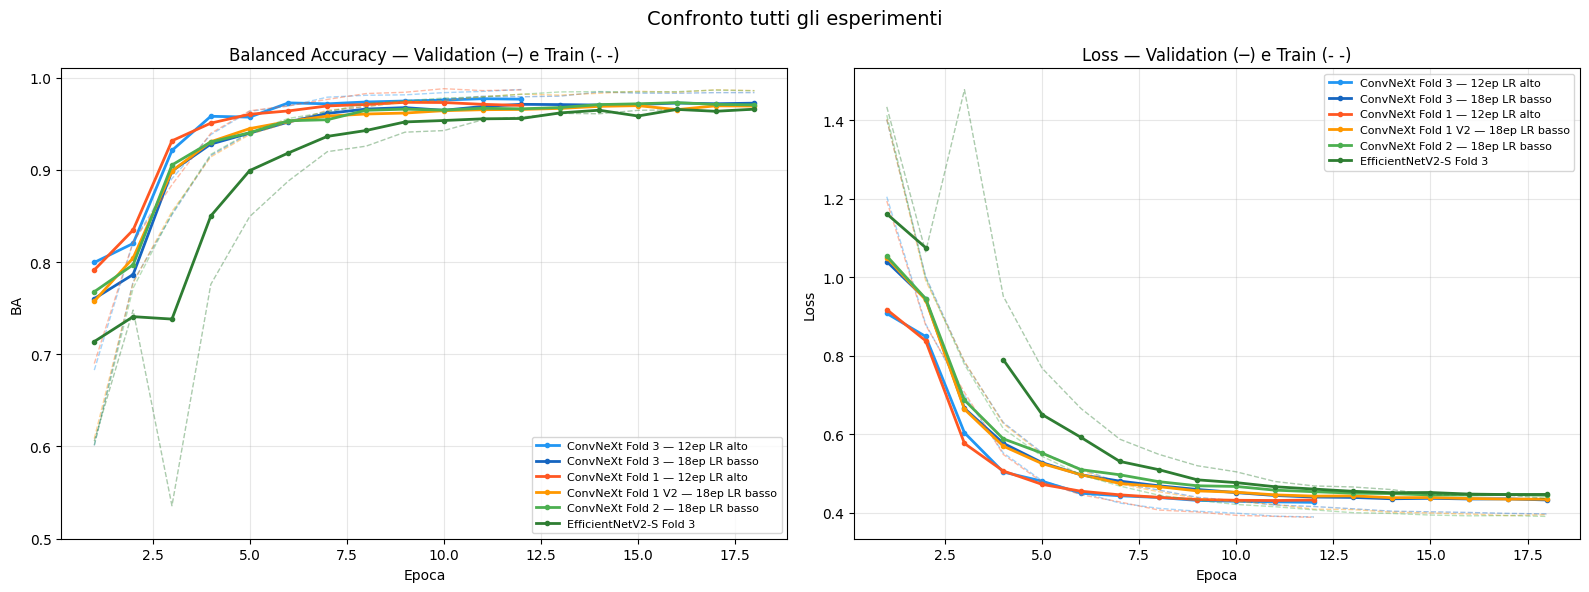


Riepilogo Best BA validation:


,Epoche,Best BA val,Best epoch
Esperimento,,,
ConvNeXt Fold 3 — 12ep LR alto,12,0.9771,11
ConvNeXt Fold 3 — 18ep LR basso,18,0.9724,16
ConvNeXt Fold 1 — 12ep LR alto,12,0.9731,9
ConvNeXt Fold 1 V2 — 18ep LR basso,18,0.9696,15
ConvNeXt Fold 2 — 18ep LR basso,18,0.9728,16
EfficientNetV2-S Fold 3,18,0.9657,18


In [25]:
# grafici comparativi
import matplotlib.pyplot as plt
from pathlib import Path

# cerca i CSV sia in /kaggle/working che in /kaggle/input
def trova_csv(nome_file):
    radici = [Path("/kaggle/working"), Path("/kaggle/input")]
    for r in radici:
        if r.exists():
            match = list(r.rglob(nome_file))
            if match:
                return str(match[0])
    return None

esperimenti_raw = {
    "ConvNeXt Fold 3 — 12ep LR alto":     "storia_fold3_exp1.csv",
    "ConvNeXt Fold 3 — 18ep LR basso":    "EXP2_storia_convnext_fold3_18ep_lr_basso.csv",
    "ConvNeXt Fold 1 — 12ep LR alto":     "storia_convnext_fold1_12ep.csv",
    "ConvNeXt Fold 1 V2 — 18ep LR basso": "storia_fold1_v2_18ep.csv",
    "ConvNeXt Fold 2 — 18ep LR basso":    "storia_convnext_fold2_18ep.csv",
    "EfficientNetV2-S Fold 3":            "effnetv2s_fold3_storia.csv",
}
colori = ["#2196F3", "#1565C0", "#FF5722", "#FF9800", "#4CAF50", "#2E7D32", "#9C27B0"]

fig, assi = plt.subplots(1, 2, figsize=(16, 6))
righe = []
for (nome, nome_file), colore in zip(esperimenti_raw.items(), colori):
    percorso = trova_csv(nome_file)
    if percorso is None:
        print(f"Skip (non trovato): {nome_file}")
        continue
    st = pd.read_csv(percorso); ep = st["epoca"]
    assi[0].plot(ep, st["balanced_accuracy_validation"], label=nome, color=colore, lw=2, marker="o", ms=3)
    assi[0].plot(ep, st["balanced_accuracy_train"], ls="--", color=colore, alpha=0.4, lw=1)
    assi[1].plot(ep, st["loss_validation"], label=nome, color=colore, lw=2, marker="o", ms=3)
    assi[1].plot(ep, st["loss_train"], ls="--", color=colore, alpha=0.4, lw=1)
    best_ba = st["balanced_accuracy_validation"].max()
    best_ep = int(st.loc[st["balanced_accuracy_validation"].idxmax(), "epoca"])
    righe.append({"Esperimento": nome, "Epoche": len(st),
                  "Best BA val": round(best_ba, 4), "Best epoch": best_ep})

assi[0].set_title("Balanced Accuracy — Validation (─) e Train (- -)")
assi[0].set_xlabel("Epoca"); assi[0].set_ylabel("BA")
assi[0].legend(fontsize=8); assi[0].grid(alpha=0.3); assi[0].set_ylim(0.5, 1.01)
assi[1].set_title("Loss — Validation (─) e Train (- -)")
assi[1].set_xlabel("Epoca"); assi[1].set_ylabel("Loss")
assi[1].legend(fontsize=8); assi[1].grid(alpha=0.3)
plt.suptitle("Confronto tutti gli esperimenti", fontsize=14)
plt.tight_layout(); plt.show()

if righe:
    print("\nRiepilogo Best BA validation:")
    display(pd.DataFrame(righe).set_index("Esperimento"))